In [2]:
df = prep_for_modelling(f"/scratch/hydro4/users/kv25483/FutureFlood/Data/EventDetails_v4/all_catchments_with_topo.pkl", 
                        remove_events_with_zero_flooding = False)
df = df[df['mean_sm_2_before_event'].notna()]
# df[df['max_quartile_index_n'].isnull()][["max_precip", "max_quartile_index_n", "length", "total_acc", "length_of_active_rain"]]
# df = create_subset(df, 10000, 10)
subset_early = create_temporal_subset(df, "before", 2020)
subset_late = create_temporal_subset(df, "after", 2060)
df=subset_early

predictor_variables = [col for col in df.columns if col not in ['10cm_area', '10cm_volume', '30cm_area', '30cm_volume']]

predictor_variables = ['max_precip', 'total_acc',  
                       "hc_at_peak", 'fumax_at_peak', 
                      'se_max', 'se_min',  'sat_at_peak_new', 'sat_at_peak_old',
                      'fu_mean_m',  'fu_min_m', 'fu_max_m', 'fu_at_peak_new', 
                        "mean_sm_2_before_event",
                      #   'peak_position_ratio','d50','gini','time_based_std','dry_ratio','max_quartile_index',
         'peak_position_ratio_n','d50_n','gini_n','time_based_std_n','dry_ratio_n','max_quartile_index_n',                     
                      'peak_cell_slope_avg', 'peak_cell_elev_avg','peak_cell_elev_min','peak_cell_slope_max', 
                      #   'peak_cell_elev_max',
                       'peak_cell_water_prop', 'peak_cell_urban_prop', 'peak_cell_inside_prop',
                   # take these out because highly correlated with max_precip    
                   #"cluster_mean_intensity_t80","cluster_mean_intensity_t50","cluster_mean_intensity_t60",
           # "cluster_mean_intensity_t50", "cluster_mean_intensity_t60", "cluster_mean_intensity_t80",
                #'cluster_rain_total_t50',  'cluster_rain_total_t60','cluster_rain_total_t80', 
           'cluster_n_cells_t50', 'cluster_n_cells_t80',
                      "random_variable"]

n = 23436, p = 70
(23436,) {'count': 23436.0, 'mean': 0.522, 'std': 0.547, 'min': 0.0, '25%': 0.151, '50%': 0.377, '75%': 0.715, 'max': 7.192}
Missing values per predictor (top):
 max_precip       0
x_coord          0
y_coord          0
start_year       0
hydro_day_360    0
dtype: int64

Baseline model comparison:
                             R2  R2_sd   RMSE    MAE
model                                              
Dummy (mean)            -0.000  0.000  0.547  0.384
Ridge (linear baseline)  0.611  0.015  0.341  0.223
RandomForest             0.862  0.009  0.203  0.122
XGBoost                  0.882  0.006  0.188  0.120
[rf] outer fold 0: R2=0.874
[rf] outer fold 1: R2=0.845
[rf] outer fold 2: R2=0.864
[rf] outer fold 3: R2=0.862
[rf] outer fold 4: R2=0.860

RF nested-CV performance (mean ± sd across outer folds):
       mean     sd
R2    0.861  0.010
RMSE  0.204  0.006
MAE   0.122  0.002


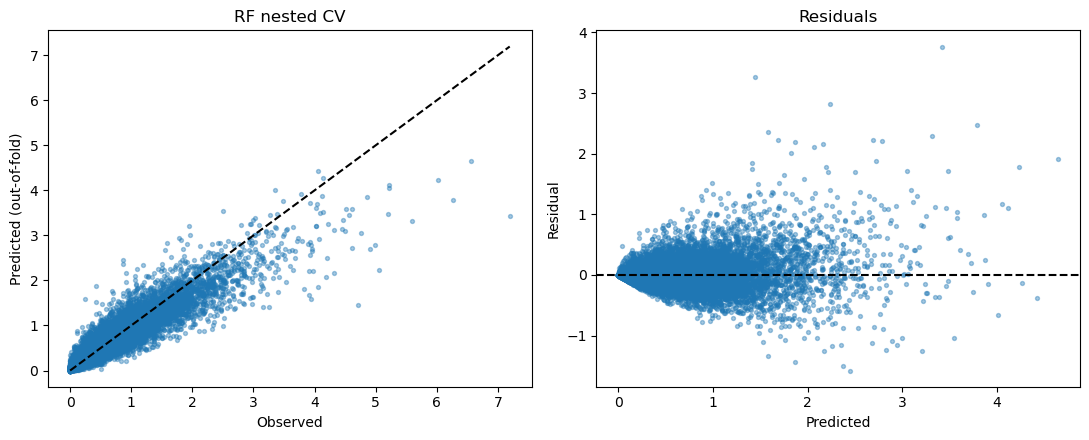

/home/kv25483/anaconda3/envs/geo_env2/lib/python3.10/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(



Final RF params: {'randomforestregressor__n_estimators': 800, 'randomforestregressor__min_samples_leaf': 2, 'randomforestregressor__max_samples': None, 'randomforestregressor__max_features': 1.0, 'randomforestregressor__max_depth': 16}


In [ ]:
data = df[predictor_variables + [TARGET] + ([GROUP_COL] if GROUP_COL else [])].dropna(subset=[TARGET])
X = data[predictor_variables]
y = data[TARGET].values
groups = data[GROUP_COL].values if GROUP_COL else None

print(f"n = {len(X)}, p = {X.shape[1]}")
print(y.shape, pd.Series(y).describe().round(3).to_dict())
print("Missing values per predictor (top):\n", X.isna().sum().sort_values(ascending=False).head())

def get_cv(n_splits):
    """Group-aware CV if groups given (prevents leakage), otherwise shuffled KFold."""
    return GroupKFold(n_splits=n_splits) if GROUP_COL else KFold(n_splits, shuffle=True, random_state=SEED)

def split(cv, X, y, groups):
    return cv.split(X, y, groups) if GROUP_COL else cv.split(X, y)

def wrap(model):
    """Optionally model log1p(target); predictions are back-transformed automatically."""
    return TransformedTargetRegressor(model, func=np.log1p, inverse_func=np.expm1) if LOG_TARGET else model

def prefix(params):
    return {f"regressor__{k}": v for k, v in params.items()} if LOG_TARGET else params

# ----------------------------------------------------------------------------
# 1. QUICK MODEL COMPARISON (default hyperparameters, repeated CV)
#    Purpose: choose model family, NOT report final performance.
# ----------------------------------------------------------------------------
candidates = {
    "Dummy (mean)": DummyRegressor(),
    "Ridge (linear baseline)": make_pipeline(SimpleImputer(), StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 20))),
    "RandomForest": make_pipeline(SimpleImputer(), RandomForestRegressor(n_estimators=300, n_jobs=N_JOBS, random_state=SEED)),
    "XGBoost": XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8,
                            colsample_bytree=0.8, n_jobs=N_JOBS, random_state=SEED),  # handles NaN natively
}
scoring = {"r2": "r2", "rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error"}

rows = []
for name, m in candidates.items():
    cv = get_cv(N_OUTER)
    res = cross_validate(wrap(m), X, y, groups=groups, cv=cv, scoring=scoring, n_jobs=1)
    rows.append({"model": name,
                 "R2": res["test_r2"].mean(), "R2_sd": res["test_r2"].std(),
                 "RMSE": -res["test_rmse"].mean(), "MAE": -res["test_mae"].mean()})
comparison = pd.DataFrame(rows).set_index("model").round(3)
print("\nBaseline model comparison:\n", comparison)

# ----------------------------------------------------------------------------
# 2. HYPERPARAMETER SEARCH SPACES
# ----------------------------------------------------------------------------
rf_space = {
    "n_estimators": [300, 500, 800],
    "max_depth": [None, 6, 10, 16, 24],
    "min_samples_leaf": [1, 2, 5, 10, 20],      # most important regulariser for RF
    "max_features": [0.2, 0.33, 0.5, 0.75, 1.0],
    "max_samples": [0.5, 0.7, 0.9, None],
}
xgb_space = {
    "n_estimators": [200, 400, 800],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "max_depth": [3, 4, 6, 8],
    "min_child_weight": [1, 5, 10],
    "subsample": [0.6, 0.8, 1.0],
    "colsample_bytree": [0.5, 0.7, 1.0],
    "reg_lambda": [0.1, 1, 10],
}

def make_search(kind, inner_cv):
    if kind == "rf":
        base = make_pipeline(SimpleImputer(), RandomForestRegressor(random_state=SEED, n_jobs=1))
        space = {f"randomforestregressor__{k}": v for k, v in rf_space.items()}
    else:
        base = XGBRegressor(random_state=SEED, n_jobs=1)
        space = xgb_space
    if LOG_TARGET:
        base = TransformedTargetRegressor(base, func=np.log1p, inverse_func=np.expm1)
        space = {f"regressor__{k}": v for k, v in space.items()}
    return RandomizedSearchCV(base, space, n_iter=N_ITER, cv=inner_cv,
                              scoring="neg_root_mean_squared_error",
                              n_jobs=N_JOBS, random_state=SEED, refit=True)

# ----------------------------------------------------------------------------
# 3. NESTED CV  -> unbiased performance estimate INCLUDING the tuning procedure
#    Outer loop: estimates generalisation. Inner loop: tunes hyperparameters.
#    Tuned params may differ per outer fold -- that's expected.
# ----------------------------------------------------------------------------
def nested_cv(kind):
    outer = get_cv(N_OUTER)
    oof_pred = np.full(len(y), np.nan)
    fold_scores, fold_best = [], []
    for k, (tr, te) in enumerate(split(outer, X, y, groups)):
        inner = get_cv(N_INNER)
        search = make_search(kind, inner)
        fit_kw = {}
        if GROUP_COL:   # inner splits must respect groups too
            inner_splits = list(inner.split(X.iloc[tr], y[tr], groups[tr]))
            search.set_params(cv=inner_splits)
        search.fit(X.iloc[tr], y[tr])
        pred = search.predict(X.iloc[te])
        oof_pred[te] = pred
        fold_scores.append({"fold": k, "R2": r2_score(y[te], pred),
                            "RMSE": np.sqrt(mean_squared_error(y[te], pred)),
                            "MAE": mean_absolute_error(y[te], pred)})
        fold_best.append(search.best_params_)
        print(f"[{kind}] outer fold {k}: R2={fold_scores[-1]['R2']:.3f}")
    return pd.DataFrame(fold_scores), oof_pred, fold_best

nested = {}
for kind in ["rf"]:
    scores, oof, best = nested_cv(kind)
    nested[kind] = dict(scores=scores, oof=oof, best=best)
    s = scores[["R2", "RMSE", "MAE"]]
    print(f"\n{kind.upper()} nested-CV performance (mean ± sd across outer folds):")
    print(pd.DataFrame({"mean": s.mean(), "sd": s.std()}).round(3))

# ----------------------------------------------------------------------------
# 4. OBSERVED vs PREDICTED & RESIDUALS (out-of-fold predictions only)
# ----------------------------------------------------------------------------
oof = nested["rf"]["oof"]
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].scatter(y, oof, s=8, alpha=0.4)
lims = [min(y.min(), oof.min()), max(y.max(), oof.max())]
ax[0].plot(lims, lims, "k--"); ax[0].set(xlabel="Observed", ylabel="Predicted (out-of-fold)", title="RF nested CV")
ax[1].scatter(oof, y - oof, s=8, alpha=0.4); ax[1].axhline(0, c="k", ls="--")
ax[1].set(xlabel="Predicted", ylabel="Residual", title="Residuals")
plt.tight_layout(); plt.show()

# ----------------------------------------------------------------------------
# 5. FINAL MODEL: tune on ALL data (CV only), then refit -> used for deployment/importance
# ----------------------------------------------------------------------------
final_cv = get_cv(N_OUTER)
final_search = make_search("rf", list(split(final_cv, X, y, groups)))
final_search.fit(X, y)
final_rf = final_search.best_estimator_
print("\nFinal RF params:", final_search.best_params_)

# ----------------------------------------------------------------------------
# 6. FEATURE IMPORTANCE
#    (a) Permutation importance on HELD-OUT folds (not training data -> avoids bias towards
#        high-cardinality/noisy features that impurity importance suffers from)
# ----------------------------------------------------------------------------
perm_rows = []
for k, (tr, te) in enumerate(split(get_cv(N_OUTER), X, y, groups)):
    m = clone(final_rf).fit(X.iloc[tr], y[tr])
    pi = permutation_importance(m, X.iloc[te], y[te], n_repeats=20, scoring="r2",
                                random_state=SEED, n_jobs=N_JOBS)
    perm_rows.append(pd.DataFrame({"feature": predictor_variables, "fold": k, "importance": pi.importances_mean}))
perm = pd.concat(perm_rows)
perm_summary = (perm.groupby("feature")["importance"].agg(["mean", "std"])
                .sort_values("mean", ascending=False))
print("\nPermutation importance (drop in R2 on held-out data):\n", perm_summary.round(4))

top = perm_summary.head(20)[::-1]
plt.figure(figsize=(6, 0.3 * len(top) + 1.5))
plt.barh(top.index, top["mean"], xerr=top["std"])
plt.xlabel("Mean drop in held-out R²"); plt.title("Permutation importance (RF)")
plt.tight_layout(); plt.show()

# (b) Correlated predictors split/mask importance -> check collinearity before interpreting
corr = X.corr(method="spearman").abs()
pairs = (corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
         .loc[lambda s: s > 0.8].sort_values(ascending=False))
print("\nHighly correlated pairs (|rho| > 0.8):\n", pairs.head(15))

# (c) Partial dependence of the top features (direction/shape of effects)
top_feats = perm_summary.index[:4].tolist()
PartialDependenceDisplay.from_estimator(final_rf, X, top_feats, kind="average", n_jobs=N_JOBS)
plt.tight_layout(); plt.show()

# (d) Optional: SHAP (pip install shap) -- local + global, handles interactions better
# import shap
# rf_core = final_rf.named_steps["randomforestregressor"]
# Xt = final_rf[:-1].transform(X)
# sv = shap.TreeExplainer(rf_core).shap_values(Xt[:2000])
# shap.summary_plot(sv, pd.DataFrame(Xt[:2000], columns=predictor_variables))